# Análisis exploratorio del catálogo de Steam

**Juan Jose Jauregui Mendoza**  
**Código: 2250920**

Actualización del análisis con el CSV original. Los valores `-1` del objetivo quedan fuera de sus estadísticas y comparaciones.

[Google Colab trabajado](https://colab.research.google.com/drive/1KegGrJNY9Q8ADhX2tiWPXe6UYcov34Wp?usp=sharing)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams.update({"figure.dpi": 160, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv("games_march2025_full.csv", sep=",", on_bad_lines="error", low_memory=False)
print("Dimensiones:", df.shape)
print("Filas duplicadas:", df.duplicated().sum())
print("Appid duplicados:", df["appid"].duplicated().sum())

Dimensiones: (89618, 47)
Filas duplicadas: 0
Appid duplicados: 0


## Limpieza estructural y valores especiales
La regla original descarta cualquier columna con algún nulo. Se reproduce para mantener trazabilidad, aunque conviene reconsiderar los textos con poca ausencia antes de modelar. Los códigos especiales numéricos requieren una revisión adicional: `isna()` no detecta `-1`. En el CSV, los 36.419 valores `-1` del objetivo coinciden con `num_reviews_total = -1`. Los 86.071 valores cero de Metacritic coinciden con la ausencia de su URL. Se tratan como puntuaciones no disponibles, conservando el original en `df`.

In [2]:
nulos = df.isna().mean() * 100
columnas = nulos[nulos > 0].index.to_list()
metadatos = ["header_image", "screenshots", "movies", "user_score", "website", "support_url", "support_email"]
df_limpio = df.drop(columns=list(set(columnas + metadatos)))
print("Después de eliminar columnas:", df_limpio.shape)
print(nulos[nulos > 0].sort_values(ascending=False).round(2))
print(pd.crosstab(df["metacritic_score"].eq(0), df["metacritic_url"].isna()))

Después de eliminar columnas: (89618, 33)
score_rank              99.96
metacritic_url          96.04
reviews                 88.39
notes                   81.43
website                 54.12
support_url             50.78
support_email           12.07
about_the_game           0.25
detailed_description     0.22
short_description        0.13
dtype: float64
metacritic_url    False  True 
metacritic_score              
False              3547      0
True                  0  86071


In [3]:
eda = df_limpio.copy()
for columna in ["pct_pos_total", "pct_pos_recent", "num_reviews_total", "num_reviews_recent", "required_age"]:
    eda.loc[eda[columna] < 0, columna] = np.nan
eda.loc[eda["metacritic_score"] == 0, "metacritic_score"] = np.nan
eda = eda.loc[eda["pct_pos_total"].between(0, 100)].copy()
print("Objetivos -1:", df["pct_pos_total"].eq(-1).sum())
print("Porcentaje sin objetivo válido:", df["pct_pos_total"].eq(-1).mean() * 100)
print("Juegos con objetivo válido:", len(eda))
print(eda["pct_pos_total"].describe())

Objetivos -1: 36419
Porcentaje sin objetivo válido: 40.63804146488429
Juegos con objetivo válido: 53199
count    53199.000000
mean        77.084381
std         17.627637
min          0.000000
25%         67.000000
50%         81.000000
75%         91.000000
max        100.000000
Name: pct_pos_total, dtype: float64


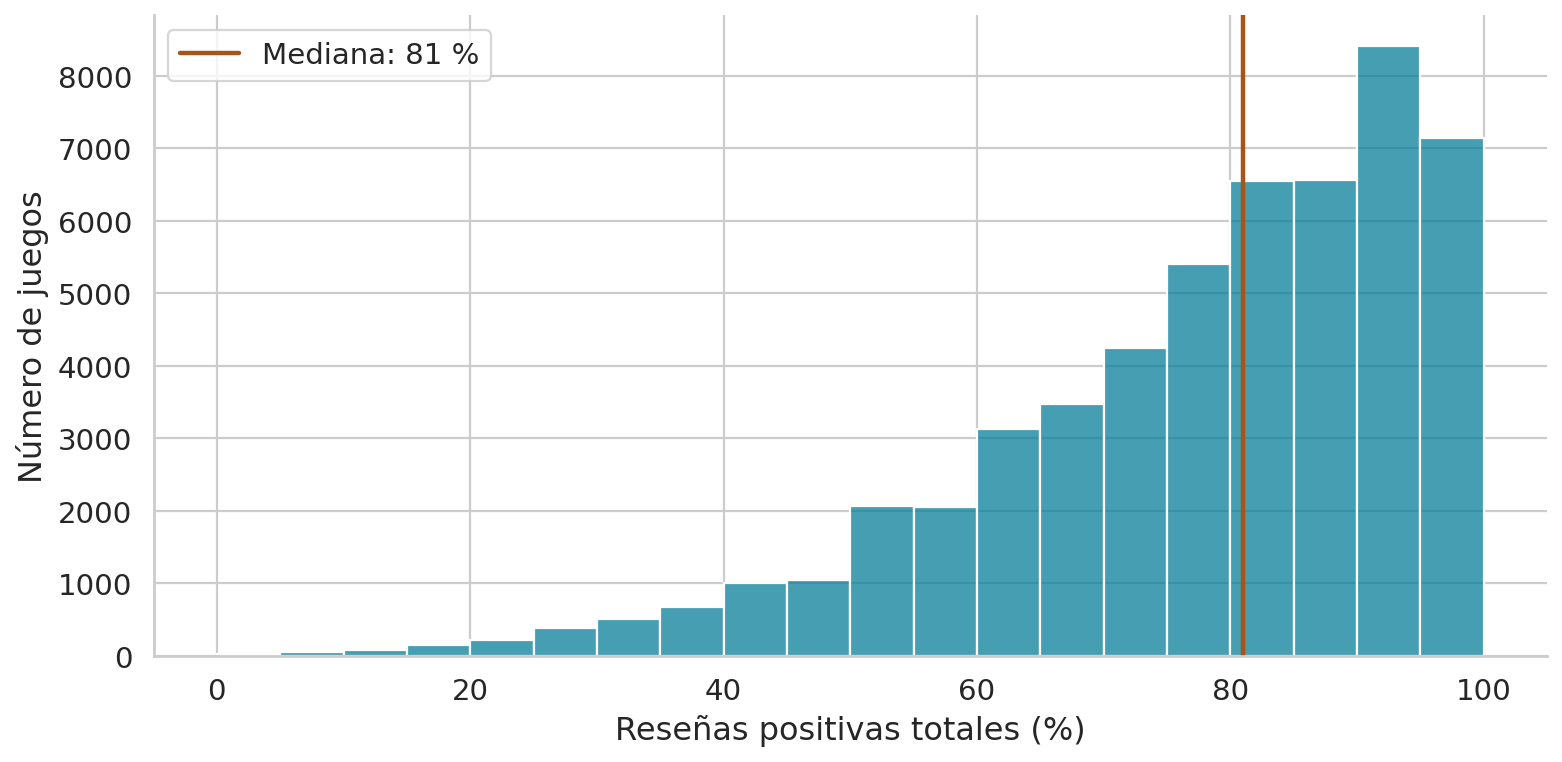

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(eda["pct_pos_total"], bins=np.arange(0, 105, 5), color="#087E99")
plt.axvline(eda["pct_pos_total"].median(), color="#A65418", linewidth=2, label="Mediana: 81 %")
plt.xlabel("Reseñas positivas totales (%)")
plt.ylabel("Número de juegos")
plt.legend()
plt.tight_layout()
plt.show()

## Categóricas seleccionadas y Windows como referencia
Base: 53.199 juegos con objetivo válido. Cada plataforma es una variable booleana independiente, de modo que los porcentajes no deben sumar 100 entre plataformas.

            Sí     No   % Sí
windows  53192      7  99.99
mac      12719  40480  23.91
linux     9003  44196  16.92


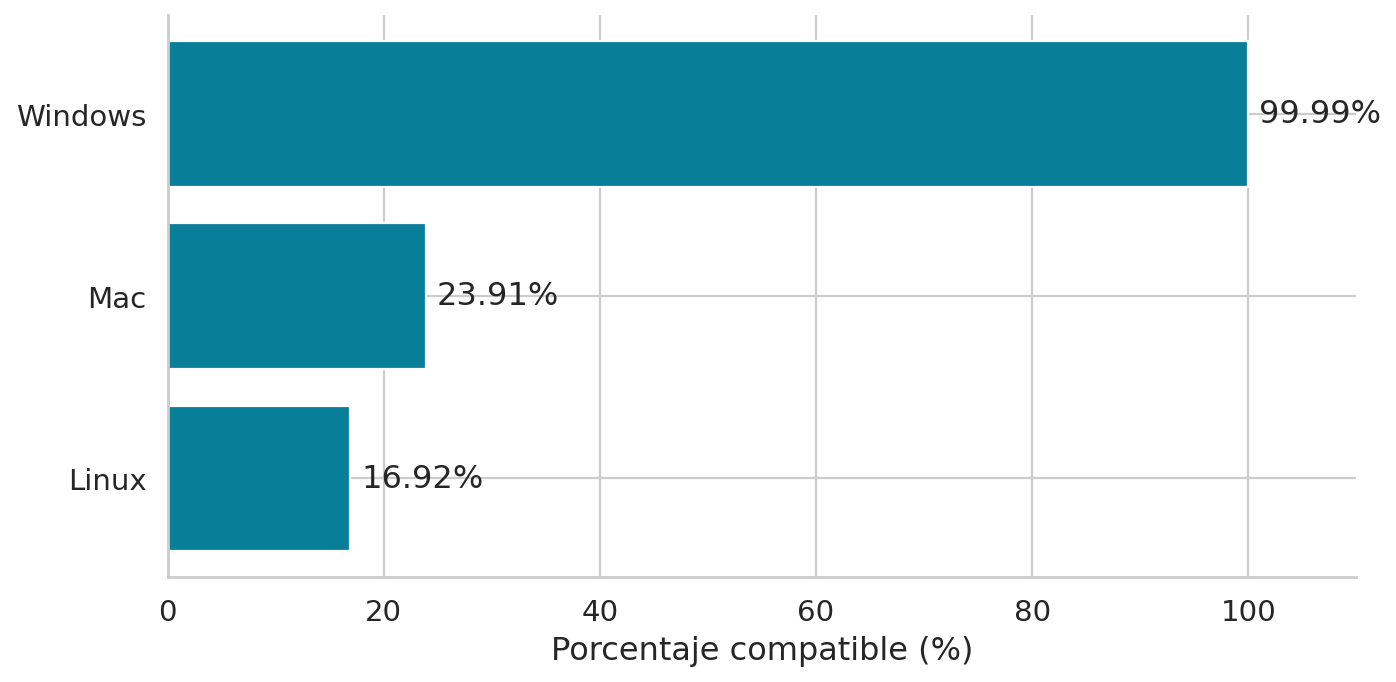

In [5]:
plataformas = eda[["windows", "mac", "linux"]]
resumen_plataformas = pd.DataFrame({"Sí": plataformas.sum(), "No": (~plataformas).sum(), "% Sí": plataformas.mean() * 100})
print(resumen_plataformas.round(2))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(["Windows", "Mac", "Linux"], resumen_plataformas["% Sí"], color="#087E99")
ax.set_xlim(0, 110)
ax.set_xlabel("Porcentaje compatible (%)")
for i, valor in enumerate(resumen_plataformas["% Sí"]):
    ax.text(valor + 1, i, f"{valor:.2f}%", va="center")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Metacritic
La distribución con todos los registros concentra 86.071 ceros. El análisis condicional siguiente utiliza los 3.512 juegos con puntuación Metacritic positiva y objetivo válido. No representa todo el catálogo.

count    3512.000000
mean       73.456435
std        10.157144
min        20.000000
25%        68.000000
50%        75.000000
75%        81.000000
max        97.000000
Name: metacritic_score, dtype: float64


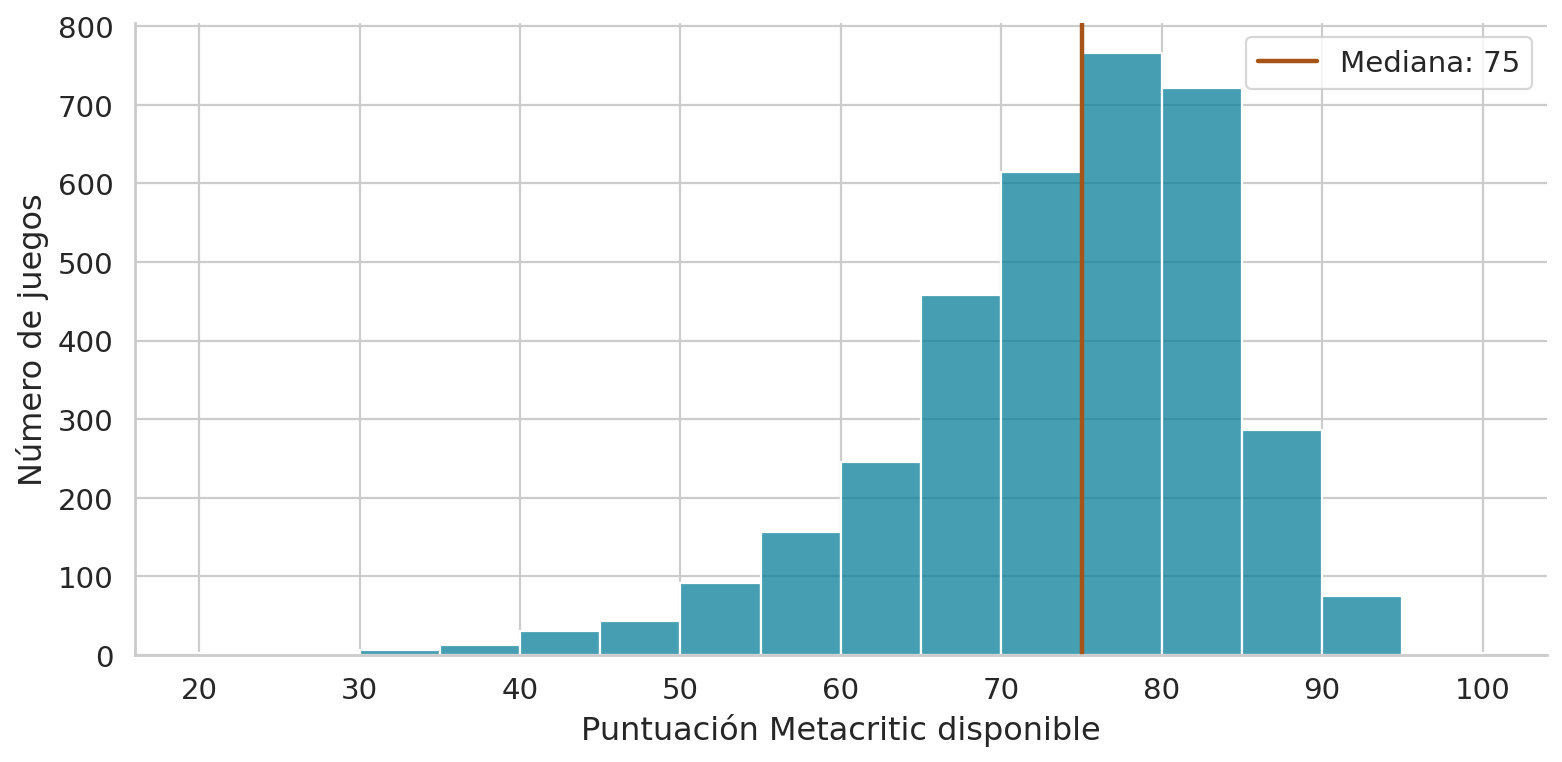

In [6]:
score = eda["metacritic_score"].dropna()
print(score.describe())
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(score, bins=np.arange(20, 105, 5), color="#087E99", ax=ax)
ax.axvline(score.median(), color="#A65418", linewidth=2, label="Mediana: 75")
ax.set_xlabel("Puntuación Metacritic disponible")
ax.set_ylabel("Número de juegos")
ax.legend()
plt.tight_layout()
plt.show()

## Precio y valores atípicos
Para mantener la comparación con el notebook inicial, esta sección usa los 89.618 registros cargados. El subconjunto por IQR aún no define el entrenamiento.

count    89618.000000
mean         7.309623
std         13.331073
min          0.000000
25%          0.990000
50%          4.990000
75%          9.990000
max        999.980000
Name: price, dtype: float64
IQR: 9.0 Límite superior: 23.490000000000002
Fuera del límite: 4146 4.62630275167935


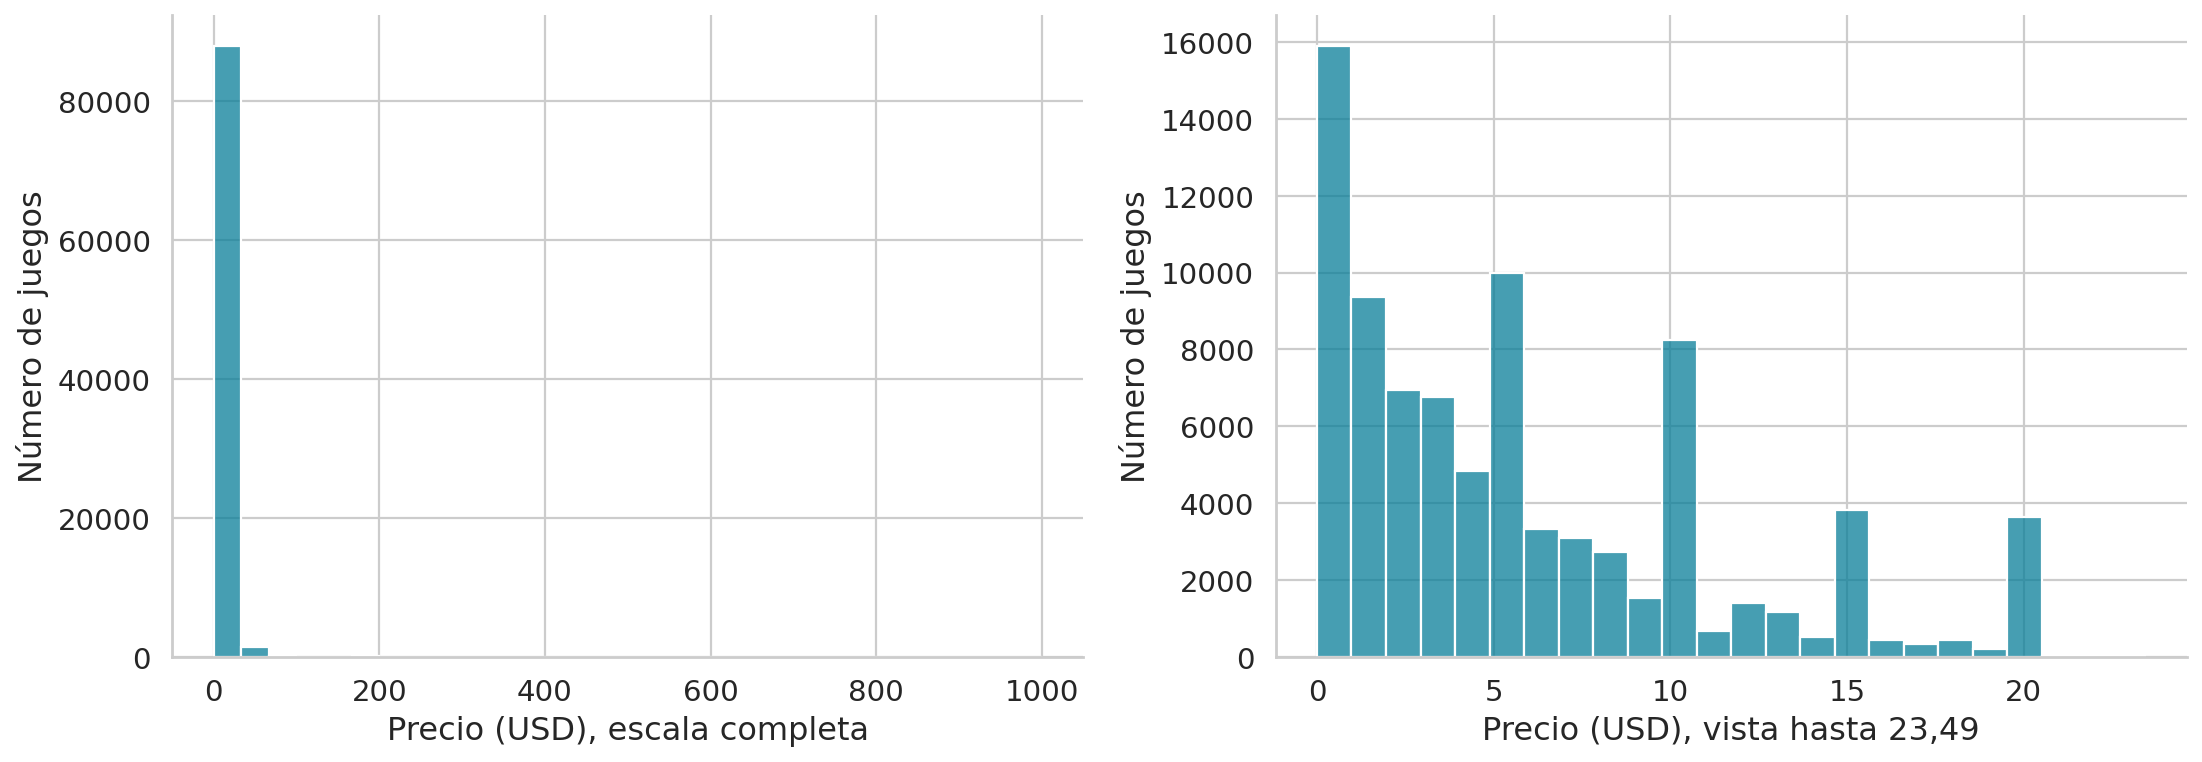

In [7]:
precio = df_limpio["price"]
q1, q3 = precio.quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
df_sin_outliers = df_limpio.loc[precio <= limite_superior].copy()
print(precio.describe())
print("IQR:", iqr, "Límite superior:", limite_superior)
print("Fuera del límite:", (precio > limite_superior).sum(), (precio > limite_superior).mean() * 100)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(precio, bins=30, color="#087E99", ax=axes[0])
axes[0].set_xlabel("Precio (USD), escala completa")
axes[0].set_ylabel("Número de juegos")
sns.histplot(precio[precio <= limite_superior], bins=24, color="#087E99", ax=axes[1])
axes[1].set_xlabel("Precio (USD), vista hasta 23,49")
axes[1].set_ylabel("Número de juegos")
plt.tight_layout()
plt.show()

## Precio cero y aceptación
Se comparan únicamente objetivos válidos. `price == 0` describe el precio observado, sin asumir que sea un modelo permanente free-to-play. La diferencia de medias no establece causalidad.

           count       mean  median
es_gratis                          
False      41770  77.267537    81.0
True       11429  76.414997    80.0
Diferencia media precio positivo menos cero: 0.852539571841703
Ausencia de objetivo por grupo (%):
price
False    44.644703
True     19.286723
Name: pct_pos_total, dtype: float64


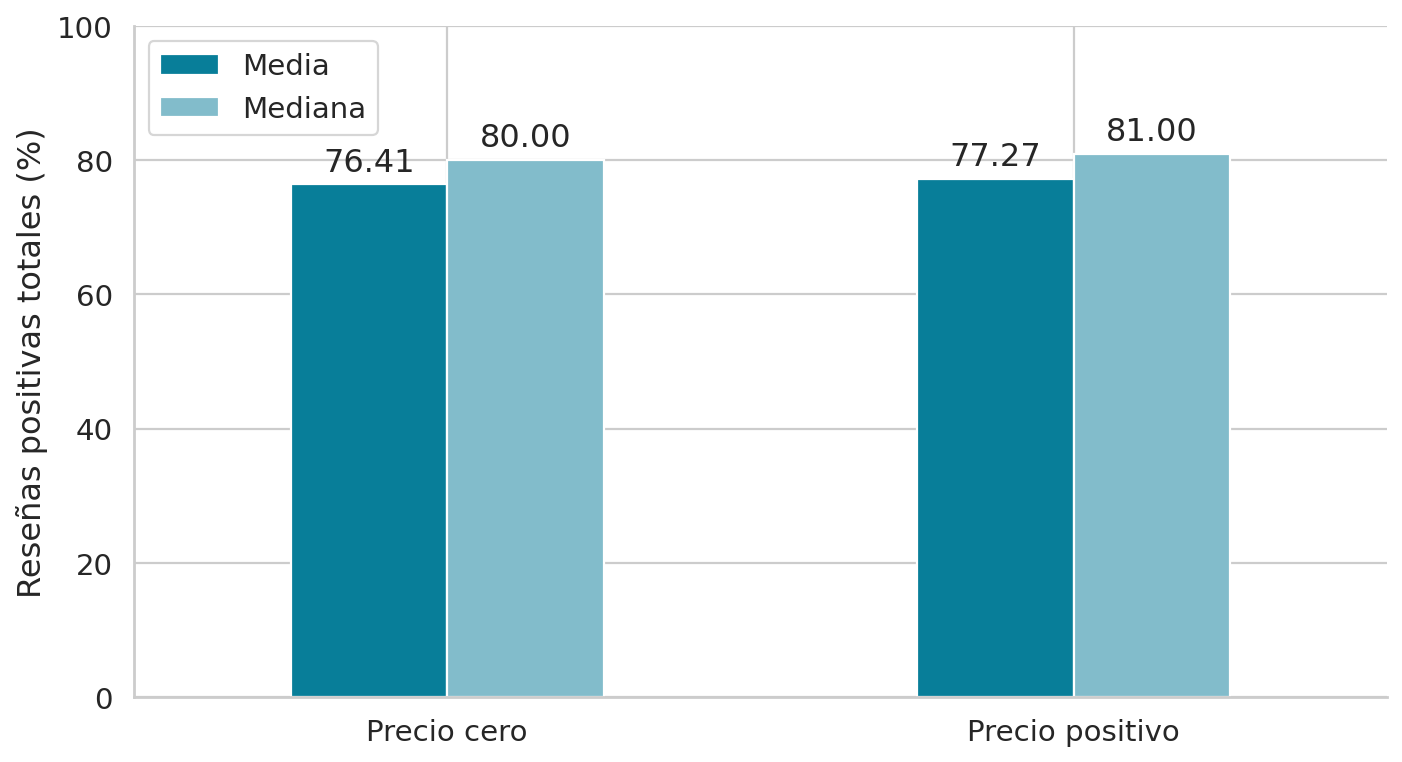

In [8]:
eda["es_gratis"] = eda["price"].eq(0)
comparacion = eda.groupby("es_gratis")["pct_pos_total"].agg(["count", "mean", "median"])
print(comparacion)
print("Diferencia media precio positivo menos cero:", comparacion.loc[False, "mean"] - comparacion.loc[True, "mean"])
print("Ausencia de objetivo por grupo (%):")
print(df.groupby(df["price"].eq(0))["pct_pos_total"].apply(lambda x: x.eq(-1).mean() * 100))
fig, ax = plt.subplots(figsize=(9, 5))
resumen = comparacion.reindex([True, False])[["mean", "median"]].copy()
resumen.index = ["Precio cero", "Precio positivo"]
resumen.columns = ["Media", "Mediana"]
resumen.plot.bar(ax=ax, color=["#087E99", "#82BCCB"], rot=0)
ax.set_ylim(0, 100)
ax.set_xlabel("")
ax.set_ylabel("Reseñas positivas totales (%)")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()

## Selección por correlación
Se excluyen el identificador `appid`, el objetivo consigo mismo y la variable auxiliar `es_gratis`. Se priorizan las seis mayores correlaciones absolutas entre las variables numéricas/booleanas conservadas. Se describen todas esas seis variables en las secciones correspondientes. La correlación usa pares disponibles, por lo que sus tamaños muestrales difieren. Seaborn dibuja la matriz calculada por pandas. Las correlaciones no demuestran causalidad ni disponibilidad previa al lanzamiento.

                         r  n pares
pct_pos_recent    0.774127     6621
metacritic_score  0.595186     3512
mac               0.091812    53199
linux             0.084114    53199
recommendations   0.032373    53199
positive          0.029100    53199


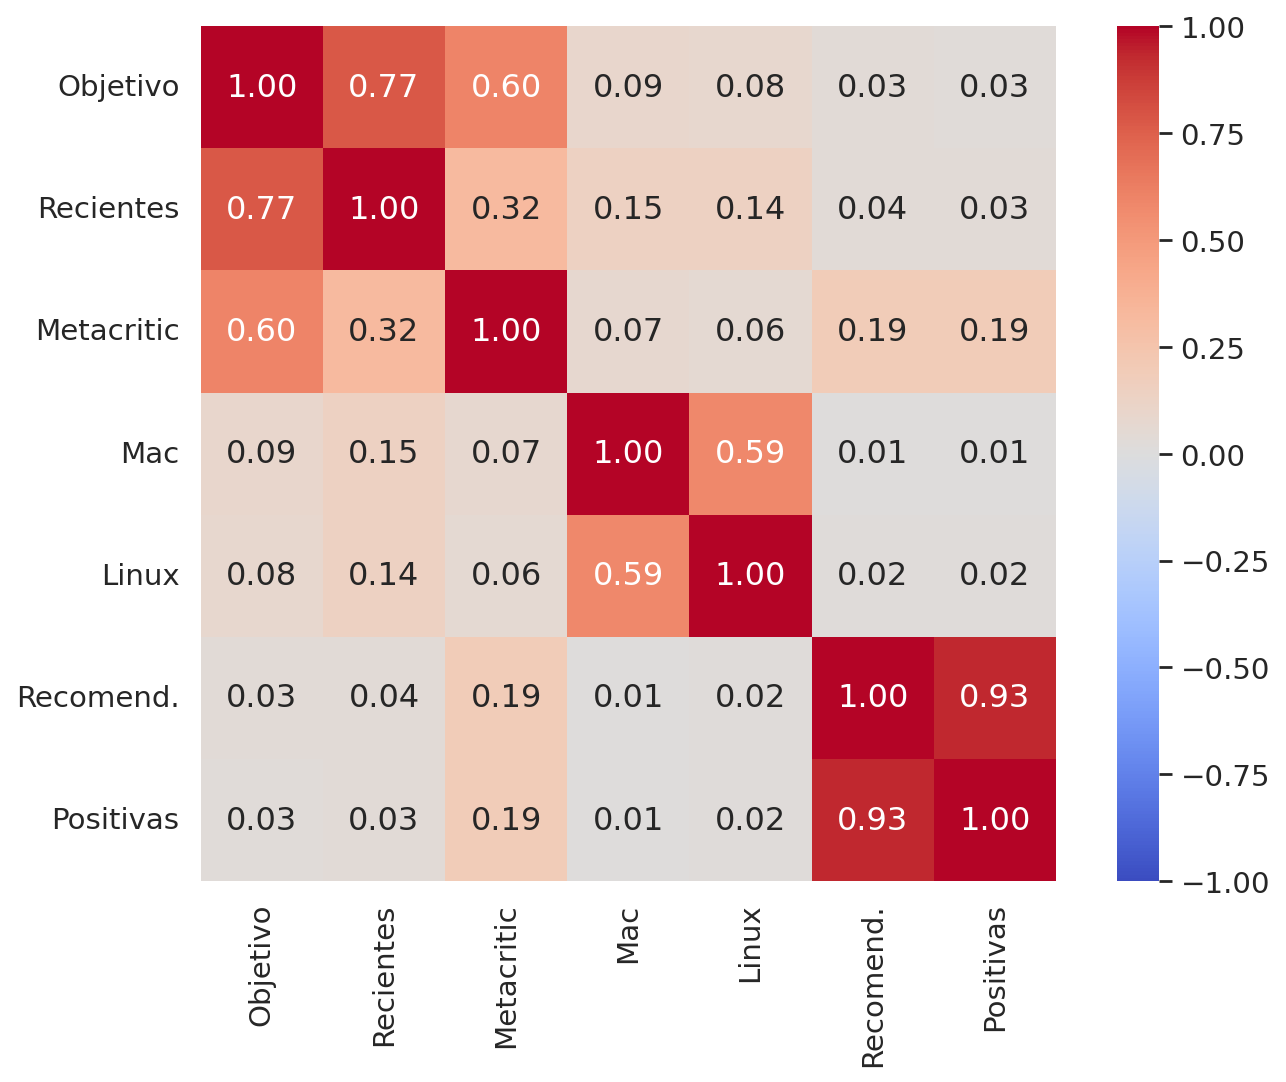

In [9]:
numericas = eda.select_dtypes(include=["number", "bool"]).drop(columns=["appid", "es_gratis"])
r = numericas.corr()["pct_pos_total"].drop("pct_pos_total")
seleccionadas = r.abs().sort_values(ascending=False).head(6).index.tolist()
print(pd.DataFrame({"r": r[seleccionadas], "n pares": numericas[seleccionadas].notna().sum()}))
columnas_mapa = ["pct_pos_total"] + seleccionadas
nombres = ["Objetivo", "Recientes", "Metacritic", "Mac", "Linux", "Recomend.", "Positivas"]
matriz = numericas[columnas_mapa].corr()
matriz.index = nombres
matriz.columns = nombres
plt.figure(figsize=(9, 7))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.tight_layout()
plt.show()

count    6621.000000
mean       82.493581
std        15.218732
min         0.000000
25%        75.000000
50%        86.000000
75%        93.000000
max       100.000000
Name: pct_pos_recent, dtype: float64


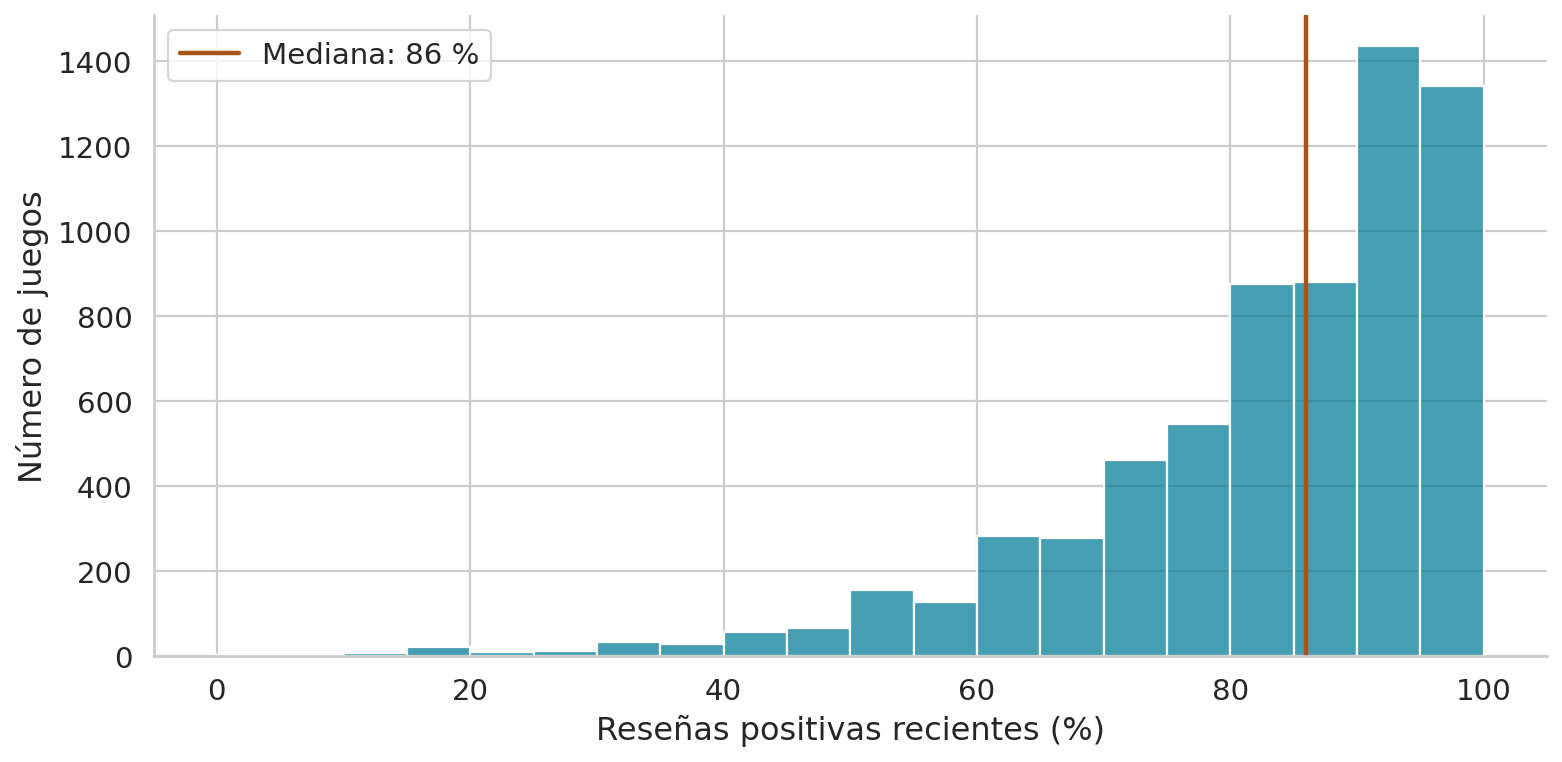

In [10]:
recientes = eda["pct_pos_recent"].dropna()
print(recientes.describe())
plt.figure(figsize=(10, 5))
sns.histplot(recientes, bins=np.arange(0, 105, 5), color="#087E99")
plt.axvline(recientes.median(), color="#A65418", linewidth=2, label="Mediana: 86 %")
plt.xlabel("Reseñas positivas recientes (%)")
plt.ylabel("Número de juegos")
plt.legend()
plt.tight_layout()
plt.show()

       recommendations      positive
count     5.319900e+04  5.319900e+04
mean      1.680022e+03  2.111757e+03
std       2.837886e+04  4.110120e+04
min       0.000000e+00  0.000000e+00
25%       0.000000e+00  1.200000e+01
50%       0.000000e+00  3.600000e+01
75%       1.590000e+02  1.820000e+02
max       4.401572e+06  7.480813e+06


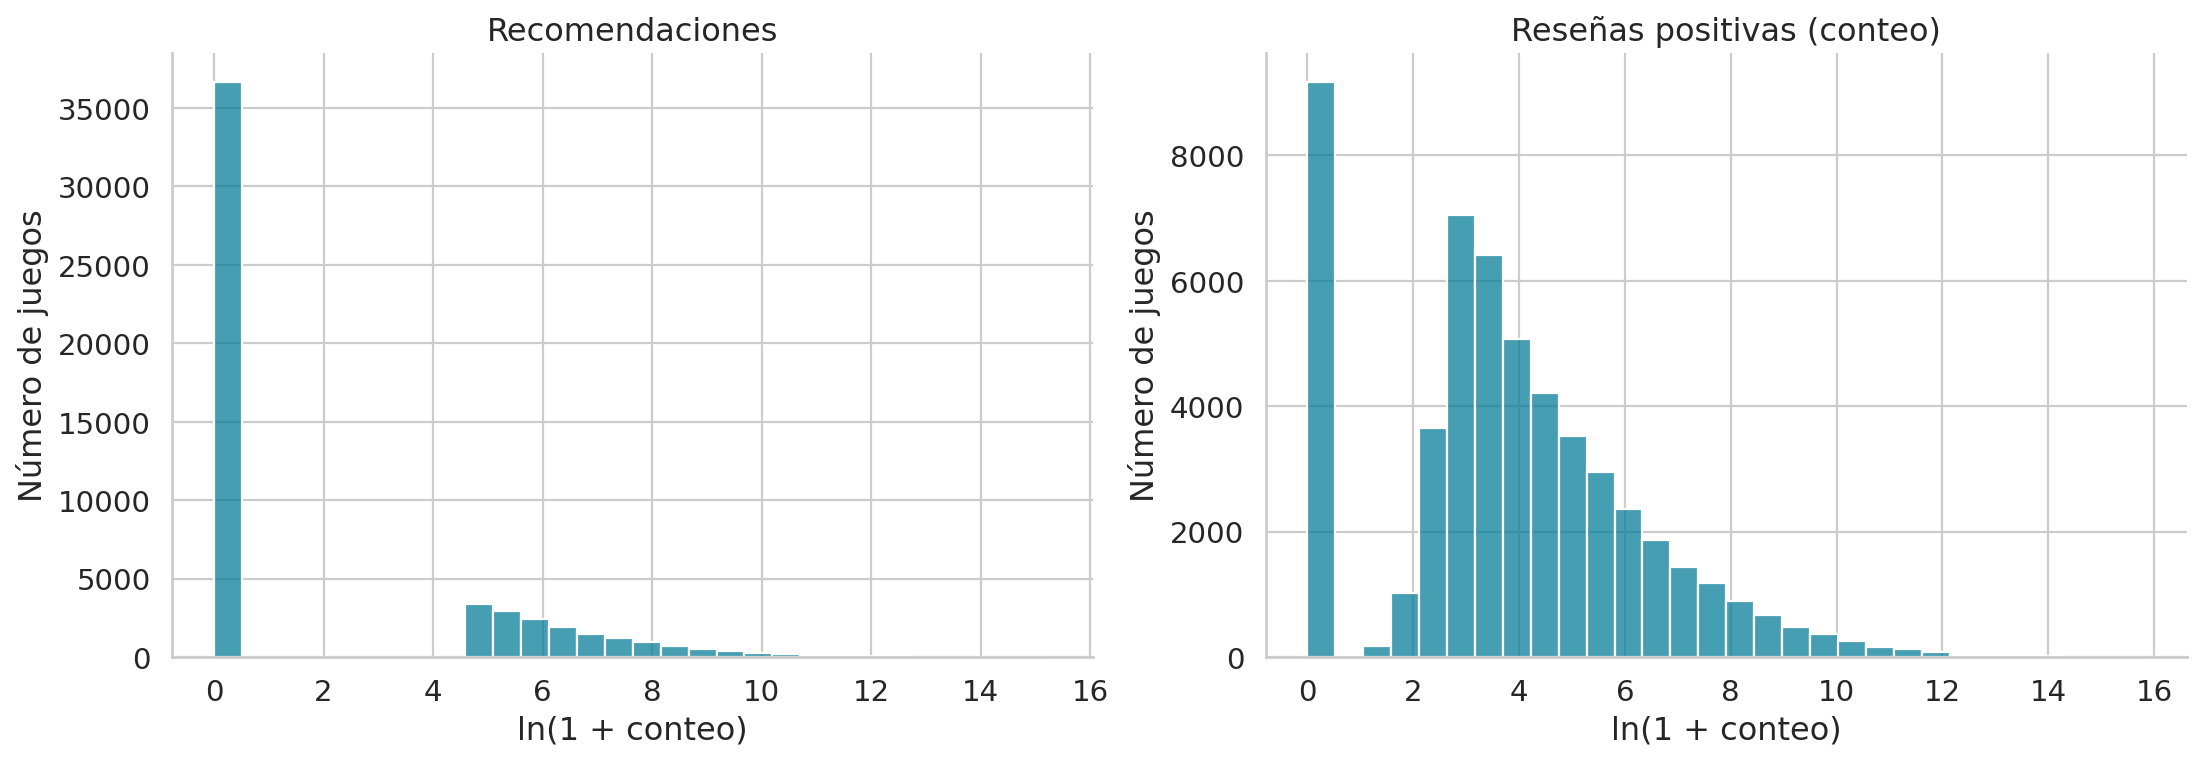

In [11]:
print(eda[["recommendations", "positive"]].describe())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, columna, titulo in zip(axes, ["recommendations", "positive"], ["Recomendaciones", "Reseñas positivas (conteo)"]):
    sns.histplot(np.log1p(eda[columna]), bins=30, ax=ax, color="#087E99")
    ax.set_title(titulo)
    ax.set_xlabel("ln(1 + conteo)")
    ax.set_ylabel("Número de juegos")
plt.tight_layout()
plt.show()

## Conclusiones y próxima etapa
- La ausencia codificada como `-1` afectaba 40,64 % del objetivo y alteraba la comparación de precios.
- Entre 53.199 objetivos válidos, la mediana es 81 % y los cuartiles son 67 % y 91 %.
- Precio positivo: media 77,27 %. Precio cero: media 76,41 %. La diferencia es 0,85 puntos, sin interpretación causal.
- Las reseñas recientes y Metacritic se correlacionan con la aceptación en subconjuntos con información disponible. Su cobertura y disponibilidad temporal limitan su uso.
- Antes de modelar: definir momento de predicción, excluir señales posteriores al lanzamiento si la predicción es anticipada, separar entrenamiento/prueba y comparar regresión con mediana base mediante MAE. La selección final y el preprocesamiento deberán ajustarse dentro del entrenamiento.
